In [ ]:
# Prepare data for fig-panelmap from all_merged.parquet
panel_cols = [
    'datasetKey',
    'decimalLatitudeStart',
    'decimalLongitudeStart',
    'year',
    'startDayOfYear',
    'biomass',
    'individualCount',
    'areaSampled'
]

df_panel = pd.read_parquet('Final/merged_all_final.parquet', columns=panel_cols).copy()

station_cols_required = ['datasetKey', 'decimalLatitudeStart', 'decimalLongitudeStart', 'startDayOfYear']

# Keep station coordinates at full precision and include startDayOfYear in station key
df_panel['decimalLatitudeStart'] = pd.to_numeric(df_panel['decimalLatitudeStart'], errors='coerce')
df_panel['decimalLongitudeStart'] = pd.to_numeric(df_panel['decimalLongitudeStart'], errors='coerce')
df_panel['year'] = pd.to_numeric(df_panel['year'], errors='coerce').astype('Int64')
df_panel['startDayOfYear'] = pd.to_numeric(df_panel['startDayOfYear'], errors='coerce').astype('Int64')

station_key = ['datasetKey', 'decimalLatitudeStart', 'decimalLongitudeStart', 'year', 'startDayOfYear']


def has_info(series):
    vals = series.astype('string').str.strip().str.lower()
    return ~(series.isna() | vals.isin(['', 'nan', 'none', '<na>']))

# Record-level flags
df_panel['has_biomass'] = has_info(df_panel['biomass']) & has_info(df_panel['areaSampled'])
df_panel['is_abundance'] = has_info(df_panel['individualCount']) & has_info(df_panel['areaSampled'])

# ---------------- Biomass coverage ----------------
biomass_station = (
    df_panel.groupby(station_key, dropna=False, as_index=False)['has_biomass']
            .agg(n_with='sum', n_total='count')
)
biomass_station['biomass_coverage'] = np.select(
    [biomass_station['n_with'] == 0, biomass_station['n_with'] == biomass_station['n_total']],
    ['None', 'Full'],
    default='partial'
)

coords_biomass = biomass_station.rename(
    columns={'decimalLongitudeStart': 'lon', 'decimalLatitudeStart': 'lat'}
)[['lon', 'lat', 'biomass_coverage']].copy()
coords_biomass = coords_biomass[
    (coords_biomass['lat'] >= -90) & (coords_biomass['lat'] <= 90) &
    (coords_biomass['lon'] >= -180) & (coords_biomass['lon'] <= 180)
]

drawing_order_biomass = ['None', 'partial', 'Full']
coverage_colors = {
    'None': '#9DC8D2',
    'partial': '#F1C40F',
    'Full': '#2C3E50'
}

records_biomass = pd.Series({
    'None': int((~df_panel['has_biomass']).sum()),
    'Full': int(df_panel['has_biomass'].sum())
})
total_obs = int(records_biomass.sum())
labels_biomass = ['None', 'Full']
counts_biomass = [records_biomass['None'], records_biomass['Full']]
colors_biomass = ['#9DC8D2', '#2C3E50']

# ---------------- Occurrence metrics ----------------
# Record-level classification: abundance requires BOTH individualCount and areaSampled
df_panel['metric_record'] = np.where(df_panel['is_abundance'], 'Abundance', 'Presence')

metric_station = (
    df_panel.groupby(station_key, dropna=False, as_index=False)['metric_record']
            .nunique()
            .rename(columns={'metric_record': 'n_metric_types'})
)
any_abundance = (
    df_panel.groupby(station_key, dropna=False)['is_abundance']
            .any()
            .rename('any_abundance')
            .reset_index()
)
metric_station = metric_station.merge(any_abundance, on=station_key, how='left')
metric_station['metric_category'] = np.select(
    [
        metric_station['n_metric_types'] > 1,
        metric_station['any_abundance']
    ],
    ['Mixed', 'Abundance'],
    default='Presence'
)

coords_metric = metric_station.rename(
    columns={'decimalLongitudeStart': 'lon', 'decimalLatitudeStart': 'lat'}
)[['lon', 'lat', 'metric_category']].copy()
coords_metric = coords_metric[
    (coords_metric['lat'] >= -90) & (coords_metric['lat'] <= 90) &
    (coords_metric['lon'] >= -180) & (coords_metric['lon'] <= 180)
]

drawing_order_metric = ['Presence', 'Mixed', 'Abundance']
colors_metric = {
    'Presence': '#9DC8D2',
    'Mixed': '#F1C40F',
    'Abundance': '#2C3E50'
}

plot_df = (
    df_panel['metric_record']
    .value_counts()
    .reindex(['Presence', 'Abundance'], fill_value=0)
    .rename_axis('Metric')
    .reset_index(name='Count')
)
plot_df['Percent'] = np.where(plot_df['Count'].sum() > 0, (plot_df['Count'] / plot_df['Count'].sum()) * 100.0, 0.0)


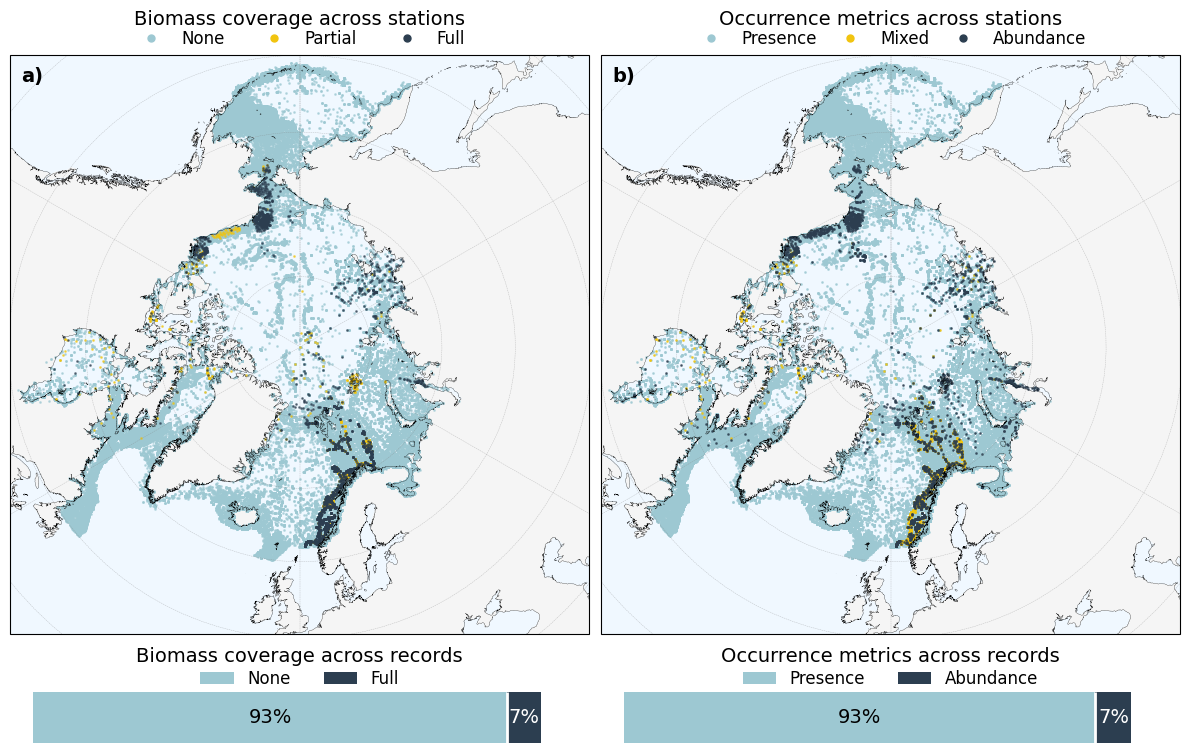

In [ ]:
#| fig-pos: "H"
#| fig-subcap: []
#| fig-names: false

# Create a figure with a custom grid layout
fig = plt.figure(figsize=(12, 10))
gs = gridspec.GridSpec(
    2, 2,  # 2 rows, 2 columns
    width_ratios=[1, 1],  # Adjust the width of each column
    height_ratios=[2, 0.1]  # Adjust the height of each row
)
# Plot 1: Biomass Coverage Map 
ax1 = fig.add_subplot(gs[0, 0], projection=ccrs.NorthPolarStereo())
ax1.set_extent([-180, 180, 50, 90], crs=ccrs.PlateCarree())
ax1.add_feature(cfeature.LAND, facecolor='whitesmoke')
ax1.add_feature(cfeature.OCEAN, facecolor='aliceblue')
ax1.coastlines(resolution='10m', linewidth=0.2, color='black')
ax1.gridlines(draw_labels=False, linewidth=0.3, color='gray', alpha=0.5, linestyle='--')
for coverage_type in drawing_order_biomass:
    subset = coords_biomass[coords_biomass['biomass_coverage'] == coverage_type]
    ax1.scatter(subset['lon'].values, subset['lat'].values,
                s=1, color=coverage_colors[coverage_type], alpha=0.6,
                label=coverage_type.capitalize(), transform=ccrs.PlateCarree())
legend_handles_biomass_map = [
    mpl.lines.Line2D([0], [0], marker='o', linestyle='None',
                     markerfacecolor=coverage_colors[k], markeredgecolor=coverage_colors[k],
                     markersize=5, label=k.capitalize())
    for k in drawing_order_biomass
]
ax1.legend(handles=legend_handles_biomass_map, loc='upper center', bbox_to_anchor=(0.5, 1.07), fontsize=12, ncol=3, frameon=False)
ax1.set_title('Biomass coverage across stations', pad=22, fontsize=14)
ax1.text(0.02, 0.98, 'a)', transform=ax1.transAxes, ha='left', va='top', fontsize=14, fontweight='bold', zorder=10)

# Plot 2: Sampling Metrics Map (Top-right, larger height)
ax2 = fig.add_subplot(gs[0, 1], projection=ccrs.NorthPolarStereo())
ax2.set_extent([-180, 180, 50, 90], crs=ccrs.PlateCarree())
ax2.add_feature(cfeature.LAND, facecolor='whitesmoke')
ax2.add_feature(cfeature.OCEAN, facecolor='aliceblue')
ax2.coastlines(resolution='10m', linewidth=0.2, color='black')
ax2.gridlines(draw_labels=False, linewidth=0.3, color='gray', alpha=0.5, linestyle='--')
for cat in drawing_order_metric:
    sub = coords_metric[coords_metric['metric_category'] == cat]
    ax2.scatter(sub['lon'].values, sub['lat'].values, s=1,
                color=colors_metric.get(cat, 'lightgray'), alpha=0.7,
                label=cat.capitalize(), transform=ccrs.PlateCarree())
legend_handles_metric_map = [
    mpl.lines.Line2D([0], [0], marker='o', linestyle='None',
                     markerfacecolor=colors_metric[k], markeredgecolor=colors_metric[k],
                     markersize=5, label=k)
    for k in drawing_order_metric
]
ax2.legend(handles=legend_handles_metric_map, loc='upper center', bbox_to_anchor=(0.5, 1.07), fontsize=12, ncol=3, frameon=False, columnspacing=1)
ax2.set_title('Occurrence metrics across stations', pad=22, fontsize=14)
ax2.text(0.02, 0.98, 'b)', transform=ax2.transAxes, ha='left', va='top', fontsize=14, fontweight='bold', zorder=10)

# Use the original two-category barplot order and colors
order_metrics = ['Presence', 'Abundance']
color_map_metrics = {'Presence': '#9DC8D2', 'Abundance': '#2C3E50'}

# Plot 3: Biomass Records Bar Plot (Bottom-left, smaller height)
ax3 = fig.add_subplot(gs[1, 0])
left_val = 0.0
for i, count in enumerate(counts_biomass):
    bar_color = colors_biomass[i]
    ax3.barh([0], [count], left=left_val, color=bar_color, edgecolor='none', linewidth=0)
    pct = 0 if total_obs == 0 else count / total_obs * 100.0
    x_mid = left_val + count / 2.0
    # Determine text color based on bar color brightness
    rgb = mcolors.to_rgb(bar_color)
    brightness = rgb_to_hsv(rgb)[2]  # Get the value (brightness) from HSV
    text_color = 'white' if brightness < 0.5 else 'black'
    ax3.text(x_mid, 0, f'{pct:.0f}%', ha='center', va='center', fontsize=14, color=text_color)
    left_val += count
# Add small white gaps between segments
gap_left = 0.0
for count in counts_biomass[:-1]:
    gap_left += count
    ax3.vlines(gap_left, -0.4, 0.4, colors='white', linewidth=2)
# Style for Plot 3
ax3.set_xticks([])
ax3.set_yticks([])
ax3.set_title('Biomass coverage across records', pad=20, fontsize=14)
ax3.spines['top'].set_visible(False)
ax3.spines['right'].set_visible(False)
ax3.spines['left'].set_visible(False)
ax3.spines['bottom'].set_visible(False)
ax3.grid(False)
# Add legend for Plot 3
legend_handles = [Patch(facecolor=colors_biomass[i], edgecolor='none', label=labels_biomass[i]) for i in range(len(labels_biomass))]
ax3.legend(
    handles=legend_handles,
    loc='upper center',
    bbox_to_anchor=(0.5, 1.6),  # Position the legend below the plot
    ncol=2,  # Number of columns in the legend
    frameon=False,  # Remove the legend box
    fontsize=12,
)
# Plot 4: Sampling Metrics Bar Plot (Bottom-right, smaller height)
ax4 = fig.add_subplot(gs[1, 1])
left_val = 0.0
for m in order_metrics:
    val = float(plot_df.loc[plot_df['Metric'] == m, 'Percent'].values[0]) if m in list(plot_df['Metric']) else 0.0
    bar_color = color_map_metrics[m]
    ax4.barh([0], [val], left=left_val, color=bar_color, edgecolor='none', linewidth=0)
    # Determine text color based on bar color brightness
    rgb = mcolors.to_rgb(bar_color)
    brightness = rgb_to_hsv(rgb)[2]  # Get the value (brightness) from HSV
    text_color = 'white' if brightness < 0.5 else 'black'
    ax4.text(left_val + val / 2, 0, f'{val:.0f}%', ha='center', va='center', fontsize=14, color=text_color)
    left_val += val
# Add small white gaps between segments
gap_left = 0.0
for m in order_metrics[:-1]:
    # Safely get percent for the metric, default to 0.0 when missing
    val_gap = float(plot_df.loc[plot_df['Metric'] == m, 'Percent'].values[0]) if m in list(plot_df['Metric']) else 0.0
    gap_left += val_gap
    ax4.vlines(gap_left, -0.4, 0.4, colors='white', linewidth=2)
# Style for Plot 4
ax4.set_xticks([])
ax4.set_yticks([])
ax4.set_title('Occurrence metrics across records', pad=20, fontsize=14)
ax4.spines['top'].set_visible(False)
ax4.spines['right'].set_visible(False)
ax4.spines['left'].set_visible(False)
ax4.spines['bottom'].set_visible(False)
ax4.grid(False)
# Add legend for Plot 4
legend_handles = [Patch(facecolor=color_map_metrics[m], edgecolor='none', label=m) for m in order_metrics]
ax4.legend(
    handles=legend_handles,
    loc='upper center',
    bbox_to_anchor=(0.5, 1.6),  # Position the legend below the plot
    ncol=2,  # Number of columns in the legend
    frameon=False,  #Remove the legend box
    fontsize=12,
)
# Adjust layout
plt.tight_layout()
plt.subplots_adjust(hspace=-0.375, wspace=0.02)
# Center the bottom bars under their corresponding maps
pos1 = ax1.get_position()
pos2 = ax2.get_position()
pos3 = ax3.get_position()
pos4 = ax4.get_position()
bar_width_scale = 0.92
new_w1 = pos1.width * bar_width_scale
new_w2 = pos2.width * bar_width_scale
ax3.set_position([pos1.x0 + (pos1.width - new_w1) / 2, pos3.y0, new_w1, pos3.height])
ax4.set_position([pos2.x0 + (pos2.width - new_w2) / 2, pos4.y0, new_w2, pos4.height])
 
plt.savefig('Figures/panel_biomass_abundance.png', dpi=300, bbox_inches='tight', facecolor='white')



In [ ]:
# Load and process data for the map (Number of records per station)
station_counts_path = 'Final/all_stations.parquet'
df_taxa = pd.read_parquet(station_counts_path)

# Validate required records column
if 'uniqueAphiaIDCount' not in df_taxa.columns:
    raise KeyError("Column 'uniqueAphiaIDCount' not found in Final/all_stations.parquet")

# Shared station definition used in the manuscript, year and startDayOfYear optional
station_cols_full = ['datasetKey', 'decimalLatitudeStart', 'decimalLongitudeStart', 'year', 'startDayOfYear']
station_cols_required = ['datasetKey', 'decimalLatitudeStart', 'decimalLongitudeStart']


def apply_station_definition(df, value_cols):
    """Apply station-level de-duplication; keep rows with missing optional fields."""
    if set(station_cols_required).issubset(df.columns):
        out = df.copy()
        out['decimalLatitudeStart'] = pd.to_numeric(out['decimalLatitudeStart'], errors='coerce')
        out['decimalLongitudeStart'] = pd.to_numeric(out['decimalLongitudeStart'], errors='coerce')

        if 'year' in out.columns:
            out['year'] = pd.to_numeric(out['year'], errors='coerce').round().astype('Int64')

        if 'startDayOfYear' in out.columns:
            out['startDayOfYear'] = pd.to_numeric(out['startDayOfYear'], errors='coerce').astype('Int64')

        # Do NOT drop rows missing optional fields; keep them as NaN/Int64
        dedupe_cols = station_cols_required + ([ 'year' ] if 'year' in out.columns else []) + ([ 'startDayOfYear' ] if 'startDayOfYear' in out.columns else [])
        keep_cols = dedupe_cols + [c for c in value_cols if c in out.columns]
        return out[keep_cols].drop_duplicates(dedupe_cols)

    return df.copy()


# Apply station definition for taxa map when station columns are available
df_taxa = apply_station_definition(df_taxa, value_cols=['uniqueAphiaIDCount'])

# Standardize coordinate column names for downstream plotting
lon_candidates = ['decimalLongitudeStart', 'LonStart', 'decimalLongitude', 'lon', 'longitude']
lat_candidates = ['decimalLatitudeStart', 'LatStart', 'decimalLatitude', 'lat', 'latitude']

lon_col = next((c for c in lon_candidates if c in df_taxa.columns), None)
lat_col = next((c for c in lat_candidates if c in df_taxa.columns), None)

if lon_col is None or lat_col is None:
    raise KeyError("Could not find station longitude/latitude columns in Final/all_stations.parquet")

plot_df_taxa = (
    df_taxa.rename(columns={lon_col: 'lon', lat_col: 'lat'})
          .copy()
)
plot_df_taxa['lon'] = pd.to_numeric(plot_df_taxa['lon'], errors='coerce')
plot_df_taxa['lat'] = pd.to_numeric(plot_df_taxa['lat'], errors='coerce')
plot_df_taxa['uniqueAphiaIDCount'] = pd.to_numeric(plot_df_taxa['uniqueAphiaIDCount'], errors='coerce')
plot_df_taxa = plot_df_taxa.dropna(subset=['lon', 'lat', 'uniqueAphiaIDCount'])
plot_df_taxa = plot_df_taxa[
    (plot_df_taxa['lat'] >= -90) & (plot_df_taxa['lat'] <= 90) &
    (plot_df_taxa['lon'] >= -180) & (plot_df_taxa['lon'] <= 180)
]
plot_df_taxa = plot_df_taxa.sort_values('uniqueAphiaIDCount', ascending=True)

# Load and process data for binary gear-information map (station level)
stations_gear_path = 'Final/all_stations.parquet'
df_gear_station = pd.read_parquet(stations_gear_path)

# Apply the same station definition for station-level gear data (year and startDayOfYear can be missing)
df_gear_station = apply_station_definition(df_gear_station, value_cols=['gear'])

lon_col_gear = next((c for c in lon_candidates if c in df_gear_station.columns), None)
lat_col_gear = next((c for c in lat_candidates if c in df_gear_station.columns), None)

if lon_col_gear is None or lat_col_gear is None:
    raise KeyError("Could not find station longitude/latitude columns in Final/all_stations.parquet")
if 'gear' not in df_gear_station.columns:
    raise KeyError("Column 'gear' not found in Final/all_stations.parquet")

coords_gear = df_gear_station.rename(columns={lon_col_gear: 'lon', lat_col_gear: 'lat'})[['lon', 'lat', 'gear']].copy()
coords_gear['lon'] = pd.to_numeric(coords_gear['lon'], errors='coerce')
coords_gear['lat'] = pd.to_numeric(coords_gear['lat'], errors='coerce')

gear_norm = coords_gear['gear'].astype('string').str.strip().str.lower()
missing_tokens = {'', 'nan', 'none', '<na>'}
coords_gear['gear_info'] = np.where(
    coords_gear['gear'].isna() | gear_norm.isin(missing_tokens),
    'No gear info',
    'With gear info'
)

coords_gear = coords_gear.dropna(subset=['lon', 'lat'])
coords_gear = coords_gear[
    (coords_gear['lat'] >= -90) & (coords_gear['lat'] <= 90) &
    (coords_gear['lon'] >= -180) & (coords_gear['lon'] <= 180)
]

colors_gear = {'No gear info': '#9DC8D2', 'With gear info': '#2C3E50'}
drawing_order_gear = ['No gear info', 'With gear info']

# Prepare data for the gear information bar plot (record level)
df_merged_gear = pd.read_parquet('Final/merged_all_final.parquet', columns=['gear'])

gear_series = df_merged_gear['gear']
has_gear_info = gear_series.notna()
no_gear_info = gear_series.isna()

n_records = len(gear_series)
pct_with_gear = (float(has_gear_info.sum()) / float(n_records) * 100.0) if n_records > 0 else 0.0
pct_without_gear = (float(no_gear_info.sum()) / float(n_records) * 100.0) if n_records > 0 else 0.0

plot_df_gear = pd.DataFrame({
    'Gear info': ['With gear info', 'No gear info'],
    'Percent': [pct_with_gear, pct_without_gear]
})
order_gear = ['With gear info', 'No gear info']
color_map_gear = {'With gear info': '#2C3E50', 'No gear info': '#9DC8D2'}


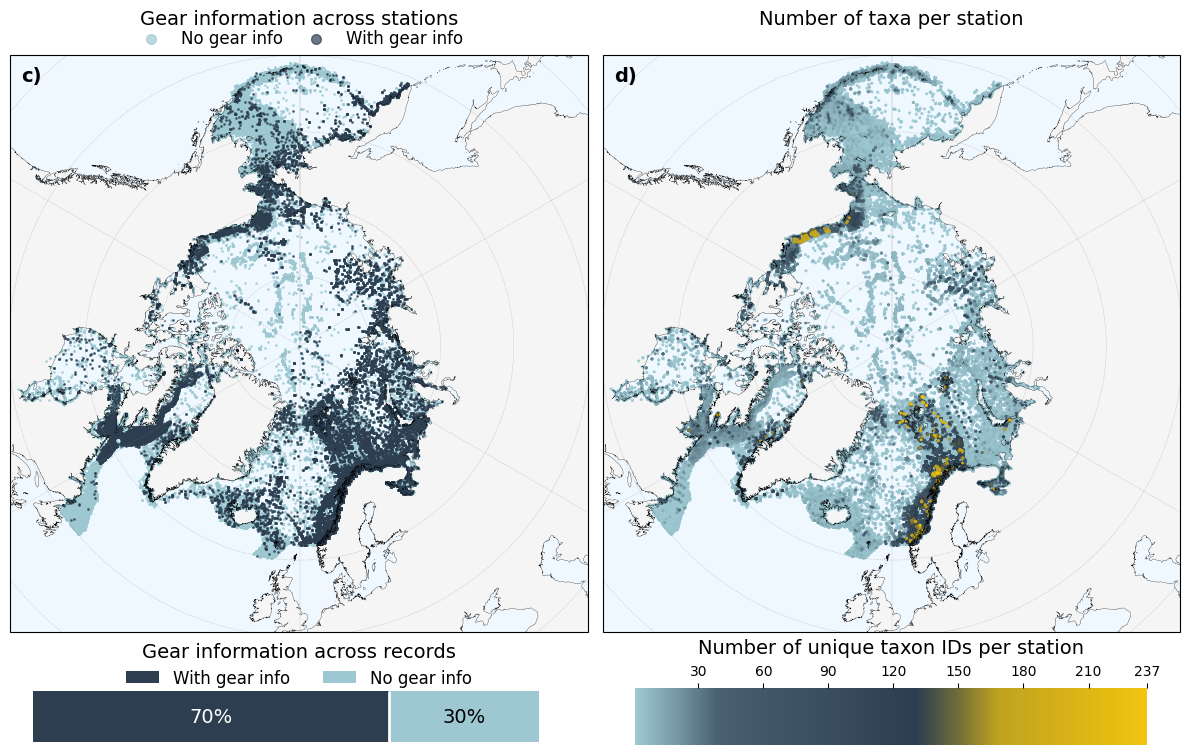

In [ ]:
#| fig-pos: "H"
#| label: fig-panelmap
#| fig-cap: "Benthic invertebrates in BENTH-MARC by a) biomass coverage, b) occurrence metrics and c) gear information across stations and records, as well as d) number of unique taxa per station. In 4 d), stations with higher numbers of taxa are drawn on top of stations with lower numbers of taxa."


# ------------------------------ NEXT FIGURE -----------------------------------------


# Create a figure with a custom grid layout
fig = plt.figure(figsize=(12, 10))
gs = gridspec.GridSpec(
    2, 2,  # 2 rows, 2 columns
    width_ratios=[1, 1],  # Adjust the width of each column
    height_ratios=[2, 0.1]  # Adjust the height of each row
)
# Subplot 1: Map with number of records per station
proj = ccrs.NorthPolarStereo()
ax1 = fig.add_subplot(gs[0, 1], projection=proj)
ax1.set_extent([-180, 180, 50, 90], crs=ccrs.PlateCarree())
ax1.add_feature(cfeature.LAND, facecolor='whitesmoke')
ax1.add_feature(cfeature.OCEAN, facecolor='aliceblue')
ax1.coastlines(resolution='10m', linewidth=0.2, color='black')
ax1.gridlines(draw_labels=False, linewidth=0.3, color='gray', alpha=0.5, linestyle='--')
# Scatter plot for records per station
vmin_records = float(plot_df_taxa['uniqueAphiaIDCount'].min())
true_max_records = float(plot_df_taxa['uniqueAphiaIDCount'].max())
display_vmax_records = true_max_records
if display_vmax_records <= vmin_records:
    display_vmax_records = vmin_records + 1.0
norm_records = mpl.colors.Normalize(vmin=vmin_records, vmax=display_vmax_records, clip=True)
taxa_break_20 = 20
taxa_break_150 = 150
norm_span = display_vmax_records - vmin_records
if norm_span <= 0:
    norm_span = 1.0
pos_20 = float(np.clip((taxa_break_20 - vmin_records) / norm_span, 0.0, 1.0))
pos_150 = float(np.clip((taxa_break_150 - vmin_records) / norm_span, 0.0, 1.0))
soft_width = min(0.08, max((pos_150 - pos_20) / 6.0, 0.02))
soft_20_low = max(0.0, pos_20 - soft_width)
soft_20_high = min(1.0, pos_20 + soft_width)
soft_150_low = max(0.0, pos_150 - soft_width)
soft_150_high = min(1.0, pos_150 + soft_width)
blue = '#9DC8D2'
dark = '#2C3E50'
gold = '#F1C40F'
blend = lambda color_a, color_b, weight: mcolors.to_hex((1 - weight) * np.array(mcolors.to_rgb(color_a)) + weight * np.array(mcolors.to_rgb(color_b)))
new_cmap = mpl.colors.LinearSegmentedColormap.from_list(
    'taxa_custom',
    [
        (0.0, blue),
        (soft_20_low, blue),
        (pos_20, blend(blue, dark, 0.35)),
        (soft_20_high, blend(blue, dark, 0.75)),
        (soft_150_low, dark),
        (pos_150, blend(dark, gold, 0.35)),
        (soft_150_high, blend(dark, gold, 0.75)),
        (1.0, gold),
    ],
)
sc = ax1.scatter(
    plot_df_taxa['lon'], plot_df_taxa['lat'],
    c=plot_df_taxa['uniqueAphiaIDCount'],
    s=5, cmap=new_cmap, norm=norm_records,
    edgecolors='k', linewidths=0,
    transform=ccrs.PlateCarree(), alpha=0.9
)
ax1.set_title('Number of taxa per station', pad=22, fontsize=14)
ax1.text(0.02, 0.98, 'd)', transform=ax1.transAxes, ha='left', va='top', fontsize=14, fontweight='bold', zorder=10)

# Subplot 2: Binary gear-information map
ax2 = fig.add_subplot(gs[0, 0], projection=ccrs.NorthPolarStereo())
ax2.set_extent([-180, 180, 50, 90], crs=ccrs.PlateCarree())
ax2.add_feature(cfeature.LAND, facecolor='whitesmoke')
ax2.add_feature(cfeature.OCEAN, facecolor='aliceblue')
ax2.coastlines(resolution='10m', linewidth=0.2, color='black')
ax2.gridlines(draw_labels=False, linewidth=0.3, color='gray', alpha=0.5, linestyle='--')
# Loop through gear info categories and plot them
for cat in drawing_order_gear:
    sub = coords_gear[coords_gear['gear_info'] == cat]
    ax2.scatter(
        sub['lon'].values,
        sub['lat'].values,
        s=1,
        color=colors_gear.get(cat, 'lightgray'),
        alpha=0.7,
        label=cat,
        transform=ccrs.PlateCarree()
    )
# Add legend
ax2.legend(
    loc='upper center',
    bbox_to_anchor=(0.5, 1.07),
    fontsize=12,
    ncol=2,
    markerscale=7,
    frameon=False,
    columnspacing=1
)
ax2.set_title('Gear information across stations', pad=22, fontsize=14)
ax2.text(0.02, 0.98, 'c)', transform=ax2.transAxes, ha='left', va='top', fontsize=14, fontweight='bold', zorder=10)

# Subplot 3: Horizontal colorbar
ax3 = fig.add_subplot(gs[1, 1])
ax3.axis('off')  # Turn off the axis for the colorbar placeholder
# Add horizontal colorbar with increased size and thickness
sm = mpl.cm.ScalarMappable(norm=norm_records, cmap=new_cmap)
sm.set_array([])
cb = fig.colorbar(sm, ax=ax3, orientation='horizontal', fraction=1, pad=0.05, aspect=9)
# Move ticks, labels, and title above the colorbar
cb.ax.xaxis.set_ticks_position('top')  # Move ticks to the top
cb.ax.xaxis.set_label_position('top')  # Move label to the top
cb.set_label(f'Number of unique taxon IDs per station', fontsize=14, labelpad=8)
cb_ticks = [0, 30, 60, 90, 120, 150, 180, 210, 240, 270, int(round(display_vmax_records))]
cb_ticks = [tick for tick in cb_ticks if vmin_records <= tick <= display_vmax_records]
cb_ticks = np.unique(cb_ticks).tolist()
cb.set_ticks(cb_ticks)
cb.ax.xaxis.set_major_formatter(FuncFormatter(lambda x, pos: f'{int(x):,}'))
cb.ax.tick_params(labelsize=10)  # Adjust tick label size
# Remove the border around the colorbar
cb.outline.set_visible(False)

# Subplot 4: Gear information bar plot (record level)
ax4 = fig.add_subplot(gs[1, 0])
left_val = 0.0
for m in order_gear:
    val = float(plot_df_gear.loc[plot_df_gear['Gear info'] == m, 'Percent'].values[0])
    bar_color = color_map_gear[m]
    ax4.barh([0], [val], left=left_val, color=bar_color, edgecolor='none', linewidth=0)
    rgb = mpl.colors.to_rgb(bar_color)
    luminance = 0.2126 * rgb[0] + 0.7152 * rgb[1] + 0.0722 * rgb[2]
    text_color = 'white' if luminance < 0.5 else 'black'
    ax4.text(left_val + val / 2, 0, f'{val:.0f}%', ha='center', va='center', fontsize=14, color=text_color)
    left_val += val
# Add small white gap between the two segments
gap_left = float(plot_df_gear.loc[plot_df_gear['Gear info'] == order_gear[0], 'Percent'].values[0])
ax4.vlines(gap_left, -0.4, 0.4, colors='white', linewidth=2)
# Style for Plot 4
ax4.set_xticks([])
ax4.set_yticks([])
ax4.set_title('Gear information across records', pad=22, fontsize=14)
ax4.spines['top'].set_visible(False)
ax4.spines['right'].set_visible(False)
ax4.spines['left'].set_visible(False)
ax4.spines['bottom'].set_visible(False)
ax4.grid(False)
# Add legend for Plot 4
legend_handles = [Patch(facecolor=color_map_gear[m], edgecolor='none', label=m) for m in order_gear]
ax4.legend(
    handles=legend_handles,
    loc='upper center',
    bbox_to_anchor=(0.5, 1.6),
    ncol=2,
    frameon=False,
    fontsize=12,
)
# Adjust layout and save the panel
plt.tight_layout()
plt.subplots_adjust(hspace=-0.375)
# Center the gear bar under the gear map
pos2 = ax2.get_position()
pos4 = ax4.get_position()
bar_width_scale = 0.92
new_w2 = pos2.width * bar_width_scale
ax4.set_position([pos2.x0 + (pos2.width - new_w2) / 2, pos4.y0, new_w2, pos4.height])
plt.savefig('Figures/panel_gear_taxa.png', dpi=300, bbox_inches='tight', facecolor='white')
plt.show()